<a href="https://colab.research.google.com/github/mdnazishpatel/Machine_learning/blob/main/Computer_vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Computer vision -04

`How computer see things and solves it`

Computer vision labraries
1. Torchvision  `https://docs.pytorch.org/vision/stable/index.html`
2. Torchvision.datasets
3. torchvision.models
4. torchvision.transforms
5. torch.utlis.data.datasets
6. torch.utlis.data.dataloader


In [ ]:
from torch.torch_version import TorchVersion
import torch
from torch import nn
import matplotlib.pyplot as plt
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

torchvision.__version__


'0.29.1+cpu'

In [ ]:
##geting a datasets we will use fashionMINST from torchvision.datasets
import torchvision
from torchvision import datasets
train_data = datasets.FashionMNIST(
    root="data", #where to get data
    train=True, # do we want the training data
    download=True, # do we want to download data
    transform =torchvision.transforms.ToTensor(), # how do we want to transoform data
    target_transform=None # how do we want to transform the labels/target
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform =ToTensor(),
    target_transform=None
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 174kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.28MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 25.0MB/s]


In [ ]:

len(train_data), len(test_data)

(60000, 10000)

In [ ]:
image, label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [ ]:
class_names = train_data.classes
class_names[0]

'T-shirt/top'

In [ ]:
class_name_toinx = train_data.class_to_idx
class_name_toinx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [ ]:
train_data.targets

tensor([9, 0, 0,  ..., 3, 0, 5])

In [ ]:

print(f"color, height , width{image.shape}labels {class_names[label]}")

color, height , widthtorch.Size([1, 28, 28])labels Ankle boot


image shape :torch.Size([1, 28, 28])


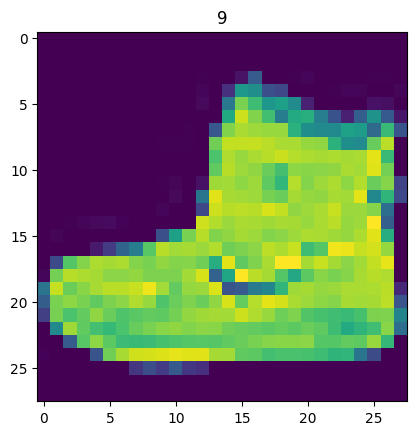

In [ ]:
## visualizing our data

import matplotlib.pyplot as plt
image, label = train_data[0]
plt.imshow(image.squeeze())
plt.title(label)
print(f"image shape :{image.shape}")
# image

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

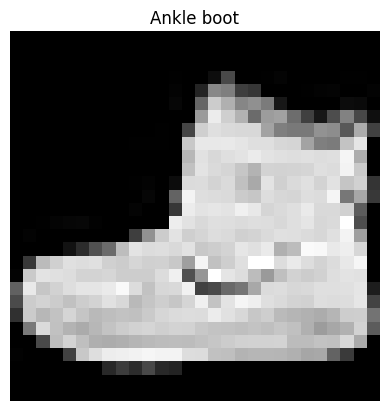

In [ ]:
plt.imshow(image.squeeze(), cmap="grey")
plt.title(class_names[label])
plt.axis(False)

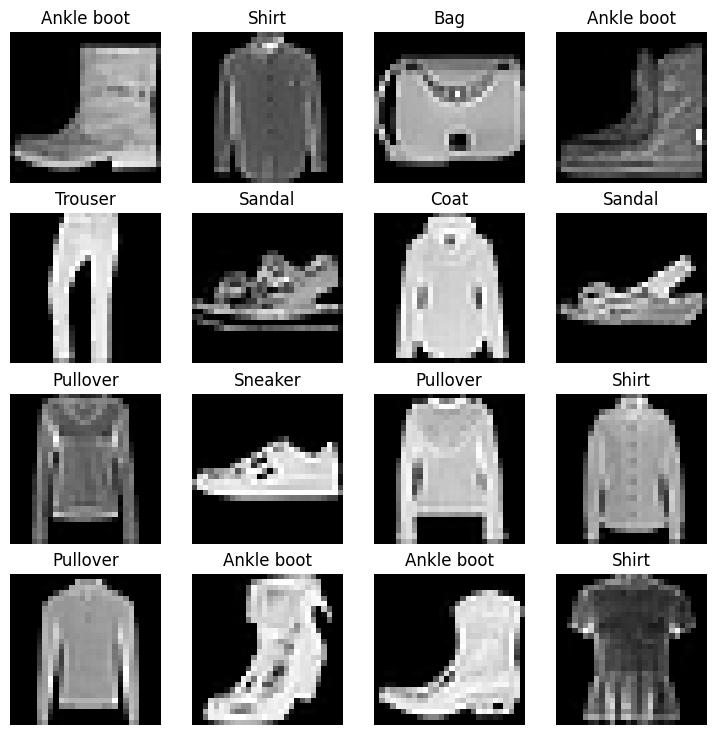

In [ ]:
from numpy import size
torch.manual_seed(42)
fig = plt.figure(figsize=(9,9))
rows , cols = 4,4
for i in range(1, rows*cols+1):
  random_idx = torch.randint(0, len(train_data), size=[1]).item()
  img , label = train_data[random_idx]
  fig.add_subplot(rows, cols,i)
  plt.imshow(img.squeeze(), cmap="grey")
  plt.title(class_names[label])
  plt.axis(False)

### Making data Loader
we have data as pytorch datasets data loader turns our data into python iterable.
And specially we want to turn our data into batches or minibaches for more effeciancy

In [ ]:
from torch.utils.data import DataLoader
BATCH_SIZE = 32
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True)
test_dataloader = DataLoader(dataset=test_data,
                             batch_size=BATCH_SIZE,
                             shuffle=False)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7f2e4acdfb60>,
 <torch.utils.data.dataloader.DataLoader at 0x7f2e48d8aad0>)

In [ ]:

print(len(train_dataloader), len(test_dataloader))

60000/32, 10000/32

1875 313


(1875.0, 312.5)

In [ ]:
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

image size :torch.Size([1, 28, 28])
Label:8, label size: torch.Size([])


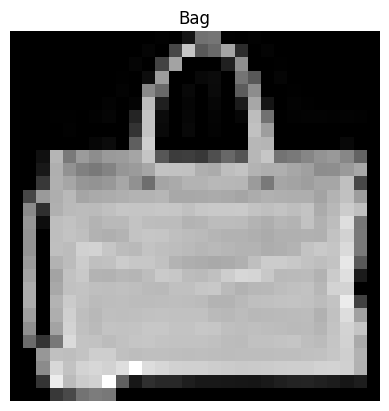

In [ ]:
## VISUALIZE
# torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.imshow(img.squeeze(), cmap="grey")
plt.title(class_names[label])
plt.axis(False)
print(f"image size :{img.shape}")
print(f"Label:{label}, label size: {label.shape}")

In [ ]:
train_data, test_data

(Dataset FashionMNIST
     Number of datapoints: 60000
     Root location: data
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset FashionMNIST
     Number of datapoints: 10000
     Root location: data
     Split: Test
     StandardTransform
 Transform: ToTensor())

### Building a model to train on this data

In [ ]:
28*28

784

In [ ]:
## use flatten layer to match shapes
from torch.nn.modules import flatten
flatten_model = nn.Flatten()

x = train_features_batch[0]

output = flatten_model(x)
print(f"shape before flatten: {x.shape}")
print(f"shape after flatten:{output.shape}")


shape before flatten: torch.Size([1, 28, 28])
shape after flatten:torch.Size([1, 784])


In [ ]:
output.squeeze()

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0039, 0.0039, 0.0000, 0.0000, 0.0078, 0.0078,
        0.0000, 0.0000, 0.0039, 0.0078, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.2863, 0.0000, 0.0000, 0.0078, 

In [ ]:
from torch import nn
class FashionMNISTModel(nn.Module):
  def __init__(self,
               input_shape: int,
               hidden_shape: int,
               output_shape: int):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape, out_features=hidden_shape),
        nn.Linear(in_features=hidden_shape, out_features=output_shape)
    )
  def forward(self, x):
    return self.layer_stack(x)



In [ ]:
torch.manual_seed(42)
model_0 = FashionMNISTModel(input_shape=784,
                            hidden_shape=10,
                            output_shape=len(class_names))

model_0

FashionMNISTModel(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [ ]:
dummy_x = torch.rand([1,28, 28])
model_0(dummy_x)

tensor([[-0.0315,  0.3171,  0.0531, -0.2525,  0.5959,  0.2112,  0.3233,  0.2694,
         -0.1004,  0.0157]], grad_fn=<AddmmBackward0>)

In [ ]:
from pathlib import Path
import requests

if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists skipping download")
else:
  print("downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

downloading helper_functions.py


In [ ]:
## setup loss  and optimizer
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.1)


In [ ]:
### CREATING A FUNCITON TO TIME OUR EXPERIMENT
#WE CAN TRACK HOW FAST OUR MODEL IS
#AND MODEL PERFORMACE

from timeit import default_timer as timer
def print_train_time(start: float,
                     end: float,
                     device: torch.device = None):

  total_time = end - start

  print(f"Train time on {device}: {total_time:.3f} seconds")
  return total_time


In [ ]:
start_time = timer()
## code here...
end_time = timer()
print_train_time(start=start_time, end=end_time, device="cpu")

Train time on cpu: 0.000 seconds


4.5849999878555536e-05

### Building our first model / Training and Testing our model
1. Loop through epoch
2. Loop through training batches perform training steps, calculate the train loss per batch
3. Loop through testing batches, perform testing steps,calculate the test loss per batch
4. print out what's happing

In [ ]:
from tqdm.auto import tqdm
torch.manual_seed(42)

train_time_start_on_cpu = timer()

epoches = 3
#training loop
for epoch in tqdm(range(epoches)):
  print(f"epoch:{epoch}\n----")
  train_loss = 0
  for batch, (x,y) in enumerate(train_dataloader):
    model_0.train()
    y_pred = model_0(x)

    loss = loss_fn(y_pred, y)
    train_loss += loss

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()

    if batch % 400 == 0:
      print(f"looked at {batch * len(x)}/ {len(train_dataloader.dataset)}samples ")
  train_loss /= len(train_dataloader)

  #testing loop
  test_loss, test_acc = 0, 0
  model_0.eval()
  with torch.inference_mode():
    for x_test, y_test in test_dataloader:
      test_pred = model_0(x_test)
      test_loss += loss_fn(test_pred, y_test)
      test_acc += accuracy_fn(y_true=y_test,
                              y_pred=test_pred.argmax(dim=1))

    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

  print(f"\nTrain loss: {train_loss:.4f} | test loss: {test_loss:.4f}, test acc: {test_acc:.2f}%")

train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start=train_time_start_on_cpu,
                                            end=train_time_end_on_cpu,
                                            device=str(next(model_0.parameters()).device))


  0%|          | 0/3 [00:00<?, ?it/s]

epoch:0
----
looked at 0/ 60000samples 
looked at 12800/ 60000samples 
looked at 25600/ 60000samples 
looked at 38400/ 60000samples 
looked at 51200/ 60000samples 

Train loss: 0.5904 | test loss: 0.5095, test acc: 82.04%
epoch:1
----
looked at 0/ 60000samples 
looked at 12800/ 60000samples 
looked at 25600/ 60000samples 
looked at 38400/ 60000samples 
looked at 51200/ 60000samples 

Train loss: 0.4763 | test loss: 0.4799, test acc: 83.20%
epoch:2
----
looked at 0/ 60000samples 
looked at 12800/ 60000samples 
looked at 25600/ 60000samples 
looked at 38400/ 60000samples 
looked at 51200/ 60000samples 

Train loss: 0.4550 | test loss: 0.4766, test acc: 83.43%
Train time on cpu: 22.023 seconds


### Making predictation and getting results

In [ ]:
torch.manual_seed(42)
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device=device):
  loss, acc = 0, 0
  model.eval()
  with torch.inference_mode():
    for x, y in tqdm(data_loader):
      x,y = x.to(device), y.to(device)
      y_pred =model(x)

      loss += loss_fn(y_pred, y)
      acc += accuracy_fn(y_true=y,
                         y_pred= y_pred.argmax(dim=1))

    loss /= len(data_loader)
    acc /= len(data_loader)

  return {"model_name": model.__class__.__name__,
          "model_loss": loss.item(),
          "model_acc": acc}
model_0 = model_0.to(device)
model_0_results = eval_model(model=model_0,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_0_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModel',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

In [ ]:
!nvidia-smi


/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
torch.cuda.is_available()

False

In [ ]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
class FashionMNISTModelv1(nn.Module):
  def __init__(self,
               input_layer:int,
               hiddeen_layer:int,
               output_layer:int):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_layer, out_features=hiddeen_layer),
        nn.ReLU(),
        nn.Linear(in_features=hiddeen_layer, out_features=hiddeen_layer),
        nn.ReLU(),
        nn.Linear(in_features=hiddeen_layer, out_features=output_layer)
    )

  def forward(self, x):
    return self.layer_stack(x)
torch.manual_seed(42)
FashionMNISTModelv1(input_layer=784,
                    hiddeen_layer=10,
                    output_layer=len(class_names))



FashionMNISTModelv1(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): ReLU()
    (3): Linear(in_features=10, out_features=10, bias=True)
    (4): ReLU()
    (5): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [ ]:
torch.manual_seed(42)
model_1 = FashionMNISTModelv1(input_layer=784,
                    hiddeen_layer=10,
                    output_layer=len(class_names)).to(device)

next(model_1.parameters()).device

device(type='cpu')

In [ ]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.01)

### Functionizing training and testing loop

In [ ]:
def train_steps(model:torch.nn.Module,
                data_loader:torch.utils.data.DataLoader,
                loss_fn:torch.nn.Module,
                optimizer:torch.optim.Optimizer,
                accuracy_fn,
                device:torch.device = device):

  train_loss, train_acc = 0,0

  model.train()

  for batch, (x,y) in enumerate(train_dataloader):
    x,y = x.to(device), y.to(device)
    y_pred = model(x)

    loss = loss_fn(y_pred, y)
    train_loss += loss
    train_acc += accuracy_fn(y_true=y,
                             y_pred=y_pred.argmax(dim=1))

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()

    if batch % 400 == 0:
      print(f"looked at {batch * len(x)}/ {len(train_dataloader.dataset)}samples ")
  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f"Trainloss: {train_loss:.5f}| train acc:{train_acc:.2f}%")


In [ ]:
def test_steps(model:torch.nn.Module,
               data_loader:torch.utils.data.DataLoader,
               loss_fn:torch.nn.Module,
               accuracy_fn,
               device:torch.device=device):
  test_loss , test_acc= 0,0
  model.eval()
  with torch.inference_mode():
    for x,y in data_loader:
      x,y = x.to(device), y.to(device)

      test_pred = model(x)
      test_loss += loss_fn(test_pred, y)
      test_acc += accuracy_fn(y_true=y,
                              y_pred=test_pred.argmax(dim=1))

    test_loss /= len(data_loader)
    test_acc /=len(data_loader)

    print(f"Test loss: {test_loss:.4f}| test acc:{test_acc:.2f}%")

In [ ]:
from timeit import default_timer as timer
torch.manual_seed(42)
train_test_start_on_gpu = timer()
epoches = 30
for epoch in tqdm(range(epoches)):
  print(f"Epoch:{epoch}\n-----")

  train_steps(model=model_1,
              data_loader=train_dataloader,
              loss_fn= loss_fn,
              optimizer=optimizer,
              accuracy_fn=accuracy_fn,
              device=device)
  test_steps(model=model_1,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn,
             device=device)

train_time_end_on_gpu = timer()
total_train_time_model_1 = print_train_time(start=train_test_start_on_gpu,
                                            end=train_time_end_on_gpu,
                                            device=device)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch:0
-----
looked at 0/ 60000samples 
looked at 12800/ 60000samples 
looked at 25600/ 60000samples 
looked at 38400/ 60000samples 
looked at 51200/ 60000samples 
Trainloss: 1.16117| train acc:59.72%
Test loss: 0.7217| test acc:72.80%
Epoch:1
-----
looked at 0/ 60000samples 
looked at 12800/ 60000samples 
looked at 25600/ 60000samples 
looked at 38400/ 60000samples 
looked at 51200/ 60000samples 
Trainloss: 0.63335| train acc:77.28%
Test loss: 0.6045| test acc:78.31%
Epoch:2
-----
looked at 0/ 60000samples 
looked at 12800/ 60000samples 
looked at 25600/ 60000samples 
looked at 38400/ 60000samples 
looked at 51200/ 60000samples 
Trainloss: 0.56101| train acc:80.28%
Test loss: 0.5701| test acc:79.88%
Epoch:3
-----
looked at 0/ 60000samples 
looked at 12800/ 60000samples 
looked at 25600/ 60000samples 
looked at 38400/ 60000samples 
looked at 51200/ 60000samples 
Trainloss: 0.52998| train acc:81.37%
Test loss: 0.5404| test acc:80.99%
Epoch:4
-----
looked at 0/ 60000samples 
looked at 1

In [ ]:
total_train_time_model_1

220.59663530499984

In [ ]:
total_train_time_model_0

22.02279066400024

In [ ]:
model_1.results = eval_model(
    model=model_1,
    data_loader=test_dataloader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn,
    device=device
)
model_1.results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModelv1',
 'model_loss': 0.4246543049812317,
 'model_acc': 85.02396166134186}

In [ ]:
model_0_results

{'model_name': 'FashionMNISTModel',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

### Building congugative neural network(cnn)
known for findding patterns  visual data

In [ ]:
image.shape

torch.Size([1, 28, 28])

In [ ]:
from torch.nn.modules.activation import ReLU
class FashionMNISTModelv2(nn.Module):
  def __init__(self,
               input_shape:int,
               hidden_units:int,
               output_shape:int):
    super().__init__()
    # Creating conv layer
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2)
    )
    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units *7*7,
                  out_features=output_shape)
    )
  def forward(self, x):
    x = self.conv_block_1(x)
    # print(x.shape)
    x = self.conv_block_2(x)
    # print(x.shape)
    x = self.classifier(x)
    # print(x.shape)
    return x



In [ ]:
torch.manual_seed(42)
model_2 = FashionMNISTModelv2(input_shape=1,
                              hidden_units=30,
                              output_shape=len(class_names)).to(device)

In [ ]:
rand_image_tensor = torch.randn(size=(1,28,28)).to(device)

model_2(rand_image_tensor.unsqueeze(0)).to(device)

tensor([[ 0.0343,  0.0440, -0.0558, -0.0103,  0.0477, -0.0521,  0.0046, -0.0306,
          0.0024,  0.0029]], grad_fn=<AddmmBackward0>)

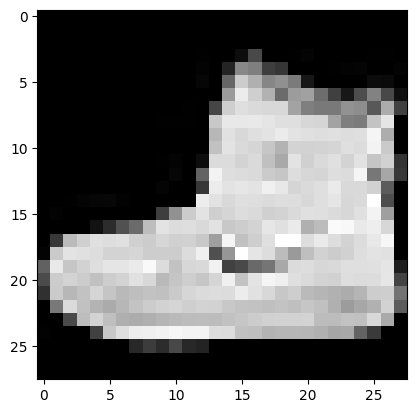

In [ ]:
plt.imshow(image.squeeze(), cmap="grey")

In [ ]:
image.shape

torch.Size([1, 28, 28])

In [ ]:
torch.manual_seed(42)

images = torch.randn(size=(32,3,64,64))
test_image= images[0]

print(f"image batch shape:{images.shape}")
print(f"single image shape:{test_image.shape}")
print(f"test image:\n{test_image}")


image batch shape:torch.Size([32, 3, 64, 64])
single image shape:torch.Size([3, 64, 64])
test image:
tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,  2.2465],
         [-1.3242, -0.1973,  0.2920,  ...,  0.5409,  0.6940,  1.8563]],

        [[-0.79

In [ ]:
model_2.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[ 1.3643e-01,  2.2603e-01, -4.5517e-01],
                        [ 4.1092e-01,  1.2816e-01, -2.0430e-01],
                        [-2.6119e-01,  1.8305e-01,  1.2069e-01]]],
              
              
                      [[[-4.3851e-01,  2.6519e-01,  4.0248e-02],
                        [-4.0834e-02,  2.0499e-01,  7.1414e-02],
                        [-2.5334e-01,  2.7939e-01, -3.2032e-02]]],
              
              
                      [[[-2.9563e-01, -9.6482e-02, -2.7503e-01],
                        [-3.0691e-01, -4.2467e-01, -2.9789e-02],
                        [-4.3649e-01, -3.8281e-01, -2.2045e-01]]],
              
              
                      [[[-4.8905e-01, -3.8757e-01, -6.2307e-01],
                        [ 1.0428e-01, -6.5183e-01,  9.4971e-02],
                        [ 1.6641e-01, -1.5068e-02,  1.8128e-01]]],
              
              
                      [[[-8.3423e-02,  1.8232e-01, -3

In [ ]:
torch.manual_seed(42)
conv_layer = nn.Conv2d(in_channels=3,
                       out_channels=10,
                       kernel_size=3,
                       stride=1,
                       padding=0)

conv_output = conv_layer(test_image.unsqueeze(0))
conv_output.shape

torch.Size([1, 10, 62, 62])

In [ ]:
## maxpool
test_image.shape

torch.Size([3, 64, 64])

In [ ]:
torch.manual_seed(42)
## Understanding maxPool
random_tensor = torch.randn(size=(1,1,2,2))
print(random_tensor)
print(random_tensor.shape)

max_pool = nn.MaxPool2d(kernel_size=2)
random_max_pool = max_pool(random_tensor)

print(random_max_pool)
print(random_max_pool.shape)

tensor([[[[0.3367, 0.1288],
          [0.2345, 0.2303]]]])
torch.Size([1, 1, 2, 2])
tensor([[[[0.3367]]]])
torch.Size([1, 1, 1, 1])


In [ ]:
print(f"test image original shape:{test_image.shape}")
print(f"test image with unsqueeze dim: {test_image.unsqueeze(0).shape}")

max_pool_layer = nn.MaxPool2d(kernel_size=2)

test_image_through_conv = conv_layer(test_image.unsqueeze(dim=0))
print(f"shape after going through convLayer:{test_image_through_conv.shape}")

test_image_through_conv_anf_maxpool = max_pool_layer(test_image_through_conv)
print(f"shape after going through convlayer and maxpool layer{test_image_through_conv_anf_maxpool.shape}")



test image original shape:torch.Size([3, 64, 64])
test image with unsqueeze dim: torch.Size([1, 3, 64, 64])
shape after going through convLayer:torch.Size([1, 10, 62, 62])
shape after going through convlayer and maxpool layertorch.Size([1, 10, 31, 31])


In [ ]:
torch.manual_seed(42)


### Loss function and optimizer for model_2

In [ ]:
from helper_functions import accuracy_fn

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_2.parameters(),
                            lr=0.1)

### Training and testing model_2

In [ ]:
torch.manual_seed(42)

from timeit import default_timer as timer

train_time_start_model_2 = timer()

epochs = 3
for epoch in tqdm(range(epochs)):
  print(f"Epoch:{epoch}\n--------")
  train_steps(model=model_2,
              data_loader=train_dataloader,
              loss_fn=loss_fn,
              optimizer=optimizer,
              accuracy_fn=accuracy_fn,
              device=device)
  test_steps(model=model_2,
             data_loader=test_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn,
             device=device)

train_time_end_model_2 = timer()
total_train_time_model_2 = print_train_time(start=train_time_start_model_2,
                                            end=train_time_end_model_2)



  0%|          | 0/3 [00:00<?, ?it/s]

Epoch:0
--------
looked at 0/ 60000samples 
looked at 12800/ 60000samples 
looked at 25600/ 60000samples 
looked at 38400/ 60000samples 
looked at 51200/ 60000samples 
Trainloss: 0.36993| train acc:86.64%
Test loss: 0.3324| test acc:88.02%
Epoch:1
--------
looked at 0/ 60000samples 
looked at 12800/ 60000samples 
looked at 25600/ 60000samples 
looked at 38400/ 60000samples 
looked at 51200/ 60000samples 
Trainloss: 0.30900| train acc:88.96%
Test loss: 0.2966| test acc:89.14%
Epoch:2
--------
looked at 0/ 60000samples 
looked at 12800/ 60000samples 
looked at 25600/ 60000samples 
looked at 38400/ 60000samples 
looked at 51200/ 60000samples 
Trainloss: 0.27430| train acc:90.19%
Test loss: 0.2770| test acc:90.22%
Train time on None: 267.424 seconds


In [ ]:
model_2_results = eval_model(
    model=model_2,
    data_loader=test_dataloader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn,
    device=device
)
model_2_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModelv2',
 'model_loss': 0.27700918912887573,
 'model_acc': 90.21565495207668}

In [ ]:
model_0_results

{'model_name': 'FashionMNISTModel',
 'model_loss': 0.47663894295692444,
 'model_acc': 83.42651757188499}

In [ ]:
model_1_results = eval_model(
    model=model_1,
    data_loader=test_dataloader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn,
    device=device
)
model_1_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModelv1',
 'model_loss': 0.4246543049812317,
 'model_acc': 85.02396166134186}

In [ ]:
import pandas as pd

comapre_results = pd.DataFrame([
    model_0_results,
    model_1_results,
    model_2_results
])
comapre_results

,model_name,model_loss,model_acc
0,FashionMNISTModel,0.476639,83.426518
1,FashionMNISTModelv1,0.424654,85.023962
2,FashionMNISTModelv2,0.277009,90.215655


### Visulaizing the comparasion

Text(0, 0.5, 'model')

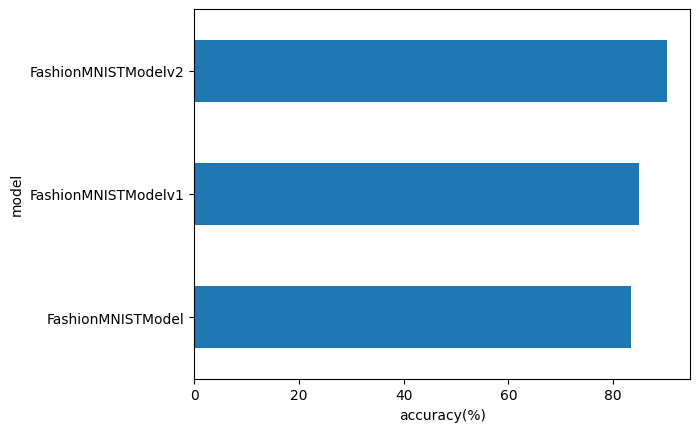

In [ ]:
import matplotlib.pyplot as plt

comapre_results.set_index("model_name")["model_acc"].plot(kind="barh")
plt.xlabel("accuracy(%)")
plt.ylabel("model")
comapre_results.set_index("model_name")["model_acc"].plot(kind="barh")
plt.xlabel("accuracy(%)")
plt.ylabel("model")

In [ ]:
comapre_results["training time"] = [total_train_time_model_0,
                                    total_train_time_model_1,
                                    total_train_time_model_2]
comapre_results

,model_name,model_loss,model_acc,training time
0,FashionMNISTModel,0.476639,83.426518,22.022791
1,FashionMNISTModelv1,0.424654,85.023962,220.596635
2,FashionMNISTModelv2,0.277009,90.215655,267.424101


### Make and evaluate random predictions with our best model

In [ ]:
def make_predictions(model:torch.nn.Module,
                     data:list,
                     device: torch.device=device):
  pred_probs = []
  model.to(device)
  model.eval()
  with torch.inference_mode():
    for sample in data:
      sample = torch.unsqueeze(sample,dim=0).to(device)
      pred_logits = model(sample)
      pred_prob = torch.softmax(pred_logits.squeeze(),dim=0)

      pred_probs.append(pred_prob.cpu())

  return torch.stack(pred_probs)


In [ ]:
img, label = test_data[0][:5]
img.shape, label

(torch.Size([1, 28, 28]), 9)

In [ ]:
import random
# random.seed(42)

test_samples =[]
test_labels = []
for sample, label in random.sample(list(test_data), k=9):
  test_samples.append(sample)
  test_labels.append(label)
test_samples[0].shape

torch.Size([1, 28, 28])

Text(0.5, 1.0, 'Shirt')

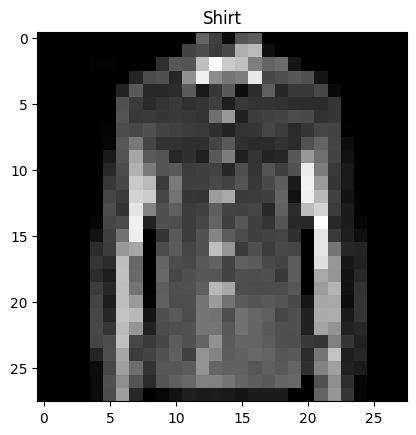

In [ ]:
plt.imshow(test_samples[0].squeeze(),cmap="grey")
plt.title(class_names[test_labels[0]])

### Making predictation

In [ ]:
pred_probs = make_predictions(
    model=model_2,
    data=test_samples,
    device=device
)
pred_probs[:2]

tensor([[1.0246e-03, 8.1428e-06, 4.6908e-03, 4.3502e-04, 2.8448e-02, 3.3362e-05,
         9.6531e-01, 5.9626e-06, 2.8020e-05, 1.3989e-05],
        [7.1688e-04, 6.8766e-01, 1.4218e-04, 1.1212e-02, 2.9938e-01, 5.2594e-05,
         1.6006e-04, 4.0708e-05, 6.2660e-04, 1.9315e-06]])

In [ ]:
pred_classes = pred_probs.argmax(dim=1)
pred_classes

tensor([6, 1, 3, 1, 3, 9, 9, 4, 2])

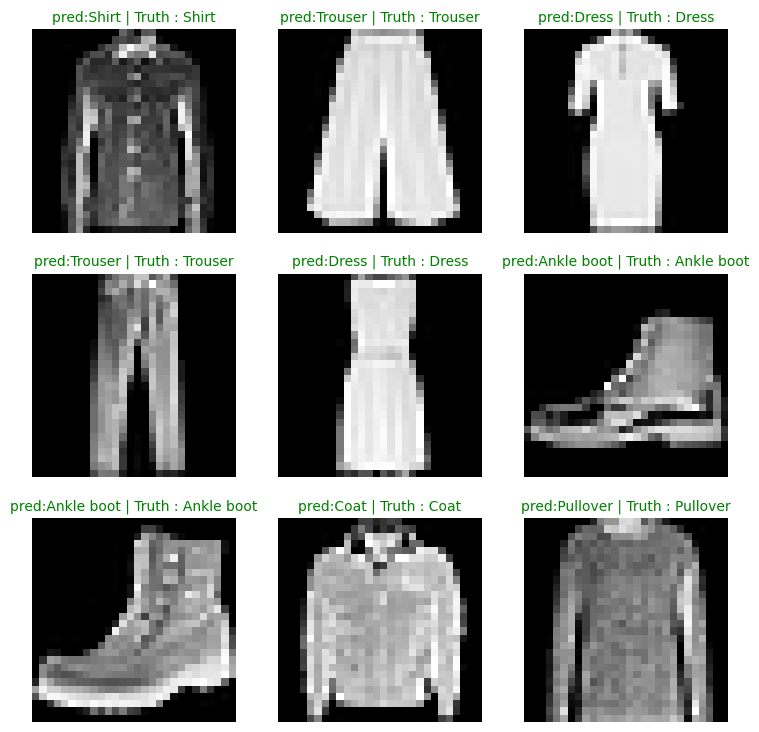

In [ ]:
##visualizing.....
plt.figure(figsize=(9,9))
nrows = 3
ncols = 3
for i, sample in enumerate(test_samples):
  plt.subplot(nrows, ncols, i+1)
  plt.imshow(sample.squeeze(), cmap="gray")

  pred_label = class_names[pred_classes[i]]

  truth_label = class_names[test_labels[i]]

  title_text = f"pred:{pred_label} | Truth : {truth_label}"

  if pred_label == truth_label:
    plt.title(title_text, fontsize=10, c="g")
  else:
      plt.title(title_text, fontsize=10, c="r")
  plt.axis(False)

### Making a confusion matrix for futher evaluation

In [ ]:
import mlxtend
from tqdm.auto  import tqdm

y_preds = []
with torch.inference_mode():
  for x, y in tqdm(test_dataloader, desc="making predictations,,,,,"):
    x,y = x.to(device), y.to(device)
    y_logits = model_2(x)
    y_pred = torch.softmax(y_logits.squeeze(), dim=0).argmax(dim=1)
    y_preds.append(y_pred.cpu())

# print(y_pred)
y_pred_tensor = torch.cat(y_preds)
y_pred_tensor

making predictations,,,,,:   0%|          | 0/313 [00:00<?, ?it/s]

tensor([9, 2, 1,  ..., 8, 1, 5])

In [ ]:
len(y_pred_tensor)

10000

In [ ]:
pip install torchmetrics

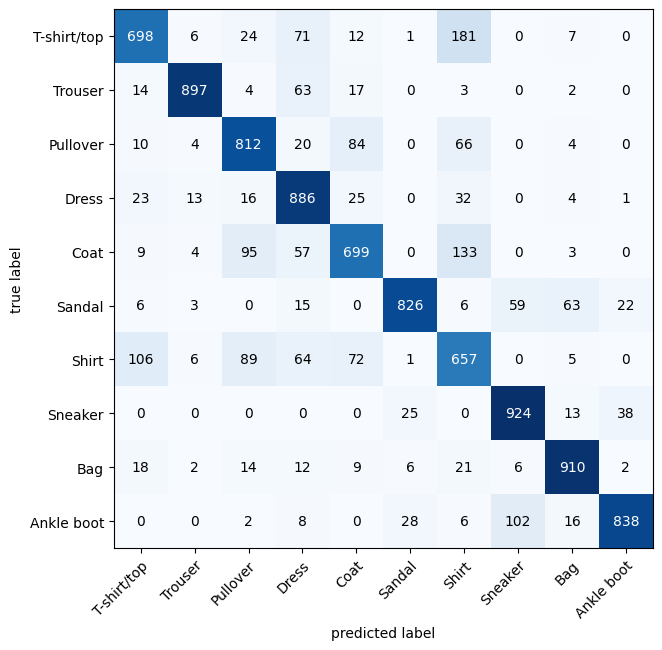

In [ ]:

from mlxtend.plotting import plot_confusion_matrix
from torchmetrics import ConfusionMatrix

confmat = ConfusionMatrix(num_classes=len(class_names),task="multiclass")
cofmat_tensor = confmat(preds=y_pred_tensor,
                        target=test_data.targets)

fig, ax = plot_confusion_matrix(
    conf_mat=cofmat_tensor.numpy(),
    class_names=class_names,
    figsize=(10,7)
)



### save and load best performaning model

In [ ]:
from os import mkdir
from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True,
                 exist_ok=True)

MODEL_NAME = "03_PYTORCH_COMPUTER_VISION_MODEL.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

print(f"saving model to:{MODEL_SAVE_PATH}")
torch.save(obj=model_2.state_dict(),
           f=MODEL_SAVE_PATH)

saving model to:models/03_PYTORCH_COMPUTER_VISION_MODEL.pth


In [ ]:
torch.manual_seed(42)

loaded_model_2 = FashionMNISTModelv2(input_shape=1,
                                     hidden_units=30,
                                     output_shape=len(class_names))

loaded_model_2.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

loaded_model_2.to(device)

FashionMNISTModelv2(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1470, out_features=10, bias=True)
  )
)

In [ ]:
##Evaluate loaded model
model_2_results

{'model_name': 'FashionMNISTModelv2',
 'model_loss': 0.27700918912887573,
 'model_acc': 90.21565495207668}

In [ ]:
##Evaluate loaded model
torch.manual_seed(42)

loaded_model_2_results = eval_model(
    model=loaded_model_2,
    data_loader=test_dataloader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn,
    device=device
)
loaded_model_2_results

  0%|          | 0/313 [00:00<?, ?it/s]

{'model_name': 'FashionMNISTModelv2',
 'model_loss': 0.27700918912887573,
 'model_acc': 90.21565495207668}

In [ ]:
torch.isclose(torch.tensor(model_2_results["model_loss"]),
                  torch.tensor(loaded_model_2_results["model_loss"]),
              atol=1e-2)

tensor(True)